# Exploratory Data Analysis

In [47]:
import pandas as pd
import matplotlib.pyplot as plt

In [48]:
df = pd.read_csv("data/final.csv")

In [49]:
df

,Date,IV,RV,VRP,ret,rf,excess_ret,ret_fwd,RV_ann,IV_ann,...,log_PE,log_PD,cay,BAA,AAA,GS10,DFSP,TMSP,RREL,cay_imputed
0,1990-02-28,4.835601,0.100781,4.734820,0.008503,0.006450,0.002053,0.017382,1.209372,58.027211,...,2.705783,3.381867,0.019955,10.14,9.22,8.47,0.92,8.463550,-0.000962,0.019955
1,1990-03-31,3.892729,0.102863,3.789866,0.023966,0.006583,0.017382,-0.033730,1.234353,46.712746,...,2.748477,3.397835,0.023025,10.21,9.37,8.59,0.84,8.583417,-0.000962,0.023025
2,1990-04-30,3.810304,0.096950,3.713354,-0.027255,0.006475,-0.033730,0.081551,1.163403,45.723650,...,2.753978,3.386751,0.023025,10.30,9.46,8.79,0.84,8.783525,-0.000962,0.023025
3,1990-05-31,3.017169,0.134186,2.882983,0.088001,0.006450,0.081551,-0.015368,1.610238,36.206031,...,2.795410,3.411676,0.023025,10.41,9.47,8.76,0.94,8.753550,-0.000962,0.023025
4,1990-06-30,2.402500,0.135575,2.266925,-0.008926,0.006442,-0.015368,-0.011587,1.626897,28.830000,...,2.830359,3.431023,0.017276,10.22,9.26,8.48,0.96,8.473558,-0.000962,0.017276
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
425,2025-07-31,2.795584,0.037021,2.758563,0.021435,0.003542,0.017894,0.015454,0.444247,33.547005,...,3.323813,4.394551,-0.044914,6.10,5.45,4.39,0.65,4.386458,-0.000107,-0.044914
426,2025-08-31,2.359296,0.113962,2.245334,0.018887,0.003433,0.015454,0.031447,1.367538,28.311551,...,3.322990,4.407418,-0.045102,6.00,5.35,4.26,0.65,4.256567,-0.000151,-0.045102
427,2025-09-30,2.650384,0.045801,2.604583,0.034714,0.003267,0.031447,0.019250,0.549612,31.804611,...,3.331752,4.429557,-0.045470,5.83,5.21,4.12,0.62,4.116733,-0.000262,-0.045470
428,2025-10-31,3.041536,0.165968,2.875568,0.022433,0.003183,0.019250,-0.001851,1.991622,36.498434,...,3.329536,4.447924,-0.045746,5.74,5.13,4.06,0.61,4.056817,-0.000297,-0.045746


In [50]:
vars_used = {
    "Rm_Rf": "excess_ret",
    "VRP": "VRP",                    
    "IV": "IV_ann",                  
    "RV": "RV_ann",
    "log_PE": "log_PE",
    "log_PD": "log_PD",
    "DFSP": "DFSP",
    "TMSP": "TMSP",
    "RREL": "RREL",
    "CAY": "cay_imputed"
}

data = df[list(vars_used.values())].copy()
data.columns = vars_used.keys()

In [51]:
summary = pd.DataFrame(index=["Mean", "Std. dev.", "Skewness", "Kurtosis", "AR(1)"],
                       columns=data.columns)

for col in data.columns:
    x = data[col].dropna()
    
    summary.loc["Mean", col] = x.mean() * 100 if col == "Rm_Rf" else x.mean()
    summary.loc["Std. dev.", col] = x.std() * 100 if col == "Rm_Rf" else x.std()
    summary.loc["Skewness", col] = x.skew()
    summary.loc["Kurtosis", col] = x.kurt() + 3
    summary.loc["AR(1)", col] = x.autocorr(1)

summary = summary.astype(float).round(2)
summary

,Rm_Rf,VRP,IV,RV,log_PE,log_PD,DFSP,TMSP,RREL,CAY
Mean,0.48,4.08,52.18,3.27,3.13,3.96,0.94,4.24,-0.00,-0.00
Std. dev.,4.27,3.55,47.74,6.63,0.33,0.28,0.37,1.93,0.00,0.02
Skewness,-0.73,3.15,3.53,8.50,2.04,-0.35,3.26,0.32,0.07,-0.34
Kurtosis,4.44,17.23,21.26,95.68,10.37,2.74,18.64,2.34,4.50,1.93
AR(1),0.00,0.76,0.76,0.48,0.98,0.99,0.96,0.99,0.97,0.99


In [52]:
corr = data.corr()
print(corr.round(2))

        Rm_Rf   VRP    IV    RV  log_PE  log_PD  DFSP  TMSP  RREL   CAY
Rm_Rf    1.00 -0.43 -0.43 -0.35    0.00    0.02 -0.09 -0.05  0.06 -0.05
VRP     -0.43  1.00  1.00  0.73    0.40   -0.02  0.58 -0.12 -0.30  0.09
IV      -0.43  1.00  1.00  0.80    0.39   -0.03  0.59 -0.12 -0.30  0.08
RV      -0.35  0.73  0.80  1.00    0.20   -0.08  0.47 -0.12 -0.22  0.02
log_PE   0.00  0.40  0.39  0.20    1.00    0.22  0.43 -0.13 -0.27 -0.14
log_PD   0.02 -0.02 -0.03 -0.08    0.22    1.00 -0.32 -0.30  0.22 -0.33
DFSP    -0.09  0.58  0.59  0.47    0.43   -0.32  1.00 -0.25 -0.27  0.00
TMSP    -0.05 -0.12 -0.12 -0.12   -0.13   -0.30 -0.25  1.00 -0.13  0.68
RREL     0.06 -0.30 -0.30 -0.22   -0.27    0.22 -0.27 -0.13  1.00 -0.19
CAY     -0.05  0.09  0.08  0.02   -0.14   -0.33  0.00  0.68 -0.19  1.00


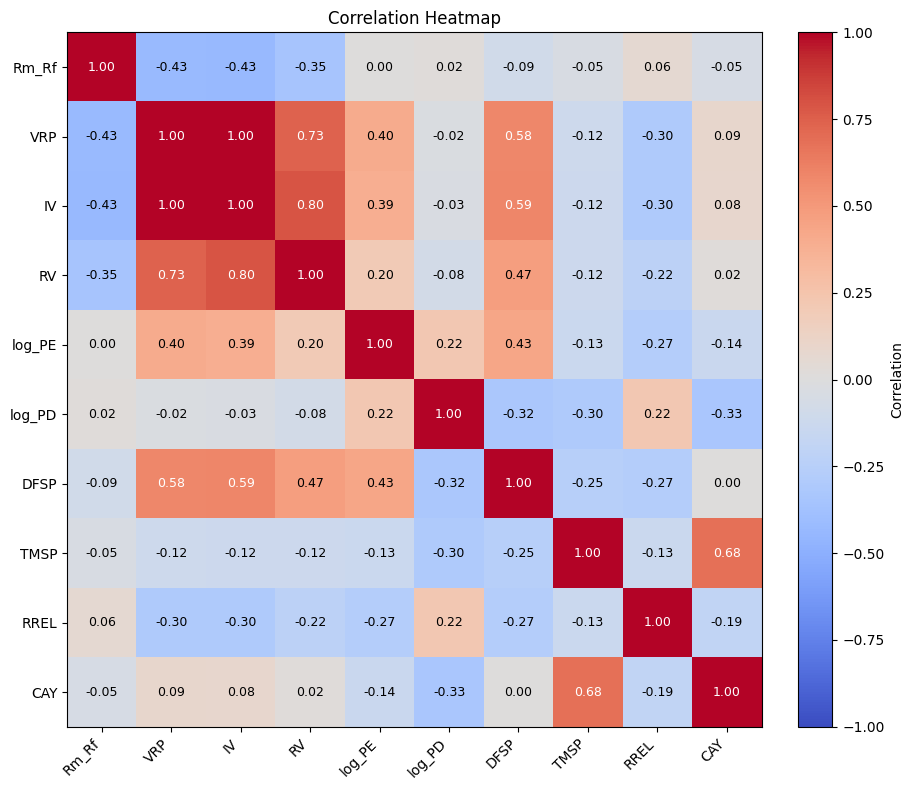

In [53]:
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.index)

# Annotate each cell with correlation value
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        val = corr.iloc[i, j]
        ax.text(
            j, i, f"{val:.2f}",
            ha="center", va="center",
            color="white" if abs(val) > 0.5 else "black",
            fontsize=9
        )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Correlation")

ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [54]:
corr = data.corr().round(2)

# nur untere Dreiecksmatrix wie im Paper
corr_lower = corr.copy().astype(object)
for r in range(corr_lower.shape[0]):
	for c in range(corr_lower.shape[1]):
		if c > r:
			corr_lower.iat[r, c] = ""

In [55]:
print("\nTable 1\nSummary statistics\n")

# Summary
print(summary.to_string())

print("\nCorrelation matrix\n")

# Correlation matrix
print(corr_lower.to_string())


Table 1
Summary statistics

           Rm_Rf    VRP     IV     RV  log_PE  log_PD   DFSP  TMSP  RREL   CAY
Mean        0.48   4.08  52.18   3.27    3.13    3.96   0.94  4.24 -0.00 -0.00
Std. dev.   4.27   3.55  47.74   6.63    0.33    0.28   0.37  1.93  0.00  0.02
Skewness   -0.73   3.15   3.53   8.50    2.04   -0.35   3.26  0.32  0.07 -0.34
Kurtosis    4.44  17.23  21.26  95.68   10.37    2.74  18.64  2.34  4.50  1.93
AR(1)       0.00   0.76   0.76   0.48    0.98    0.99   0.96  0.99  0.97  0.99

Correlation matrix

       Rm_Rf   VRP    IV    RV log_PE log_PD  DFSP  TMSP  RREL  CAY
Rm_Rf    1.0                                                       
VRP    -0.43   1.0                                                 
IV     -0.43   1.0   1.0                                           
RV     -0.35  0.73   0.8   1.0                                     
log_PE   0.0   0.4  0.39   0.2    1.0                              
log_PD  0.02 -0.02 -0.03 -0.08   0.22    1.0                       


In [56]:
df["rf"]

0      0.006450
1      0.006583
2      0.006475
3      0.006450
4      0.006442
         ...   
425    0.003542
426    0.003433
427    0.003267
428    0.003183
429    0.003150
Name: rf, Length: 430, dtype: float64